# 07 · Диагностика: где и в какой форме LoRA меняет модель

**Зачем** (JOURNAL, 2026-10-27). LoRA на тех же данных закрывает разрыв почти полностью — это маркер:
нужное поведение достижимо малым изменением. Цель следующего этапа — без градиентного обучения привести
модель туда же. Прежде чем строить методы, выясняем:

1. **Где живёт эффект.** Подставляем скрытые состояния модели с LoRA в базовую — на одном слое и в одном
   наборе позиций за раз — и смотрим, становится ли решение как у LoRA (0 — как у базы, 1 — как у LoRA).
2. **Какой он формы.** Разница активаций Δh = h_LoRA − h_база: какую её долю на новых задачах
   воспроизводит постоянный вектор (класс CAA), вектор по состоянию «подходит / не подходит» и линейное
   отображение состояния базы. Плюс поведенческая проверка: добавка каждой формы в точке решения.

Данные — train (на них учились вектор и LoRA). Ничего не подбирается; val и test не используются.
Результат разведочный.

In [1]:
%load_ext autoreload
%autoreload 2
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # Mac: неподдержанные операции -> CPU

import pandas as pd
from IPython.display import Markdown, display
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

from steering_tool_feedback.config import ExperimentConfig
from steering_tool_feedback.pipeline import Experiment
from steering_tool_feedback import journal, viz

In [2]:
cfg = ExperimentConfig.make(
    name="lora-diag-qwen3-1.7b", hypothesis="explore", notebook="notebooks/07_lora_diagnostics.ipynb",
    notes="Где и в какой форме LoRA меняет активации: подстановка LoRA → база, разбор Δh.",
    overrides={
        "model.name": "Qwen/Qwen3-1.7B",
        "data.n_tasks": 160,
        "data.generator": "v3",
        "eval.methods": ["baseline", "strong_prompt", "restate", "explicit_state",
                         "steering", "steering_gated", "tact", "lora"],
        "steer.alphas": [0.25, 0.5, 1.0, 2.0, 4.0],
    },
)
exp = Experiment(cfg)
exp.run("fit")

/Users/admin/Desktop/steering-tool-feedback/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[21:43:26] run 20261027-214322_lora-diag-qwen3-1.7b_c2afcb  ->  results/runs/20261027-214322_lora-diag-qwen3-1.7b_c2afcb
[21:43:26] data: {'train': 79, 'val': 31, 'test': 50}  types={'invariant': 41, 'changing': 112, 'stress': 7}  positions={'early': 114, 'late': 46}


baseline/train:   0%|          | 0/158 [00:00<?, ?it/s]

[21:43:26] loading model Qwen/Qwen3-1.7B …


W1027 21:43:38.121000 2001 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

... (457 outputs left out)

episodes tact/val:   0%|          | 0/58 [00:00<?, ?it/s]

episodes lora/val:   0%|          | 0/58 [00:00<?, ?it/s]

episodes lora/val:  90%|████████▉ | 52/58 [00:00<00:00, 515.33it/s]

[21:44:16] val: baseline 0.621; strong_prompt 0.569; restate 0.638; explicit_state 0.552; steering 0.655; steering_gated 0.638; tact 0.621; lora 0.948


### Диагностика

In [3]:
diag = exp.lora_diagnostics()
{k: diag[k] for k in ("n_prompts", "n_disagree", "n_control", "lora_fixes", "lora_breaks",
                      "first_token_agreement", "adapter")}

lora/train:   0%|          | 0/158 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/224 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/224 [00:00<00:49,  4.47it/s]

Loading weights: 100%|██████████| 224/224 [00:00<00:00, 823.54it/s]

lora/train:   1%|          | 1/158 [00:02<06:30,  2.49s/it]

lora/train:   1%|▏         | 2/158 [00:02<03:23,  1.31s/it]

... (311 outputs left out)

lora diagnostics:  99%|█████████▉| 155/156 [3:11:18<00:32, 32.19s/it]

lora diagnostics: 100%|██████████| 156/156 [3:12:23<00:00, 42.06s/it]

[01:04:50] lora diagnostics: 156 промптов train, решения LoRA и базы расходятся в 63; первый токен = полный скоринг в 100%


{'n_prompts': 156,
 'n_disagree': 63,
 'n_control': 20,
 'lora_fixes': 41,
 'lora_breaks': 1,
 'first_token_agreement': 1.0,
 'adapter': '684a01bfec65'}

### 1. Где живёт эффект LoRA: подстановка по слоям и позициям

layer,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
set,,,,,,,,,,,,,,,,,,,,,
all,0.31,0.41,0.50,0.59,0.67,0.71,0.81,0.92,1.02,1.12,...,1.10,1.04,0.88,0.89,0.93,0.95,0.95,0.96,0.99,1.0
decision,0.13,0.17,0.22,0.29,0.30,0.33,0.37,0.40,0.46,0.55,...,1.20,1.17,1.09,1.01,1.01,1.03,1.04,1.04,0.99,1.0
field_read,0.02,0.03,0.05,0.08,0.12,0.14,0.15,0.17,0.19,0.26,...,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0
last,0.01,0.02,0.03,0.04,0.06,0.08,0.09,0.10,0.13,0.13,...,1.23,1.21,1.32,1.17,1.08,1.10,1.11,1.12,1.00,1.0
tool_content,0.04,0.06,0.10,0.12,0.15,0.14,0.15,0.19,0.28,0.34,...,0.01,0.01,0.01,0.02,0.00,0.00,0.00,0.00,0.00,0.0


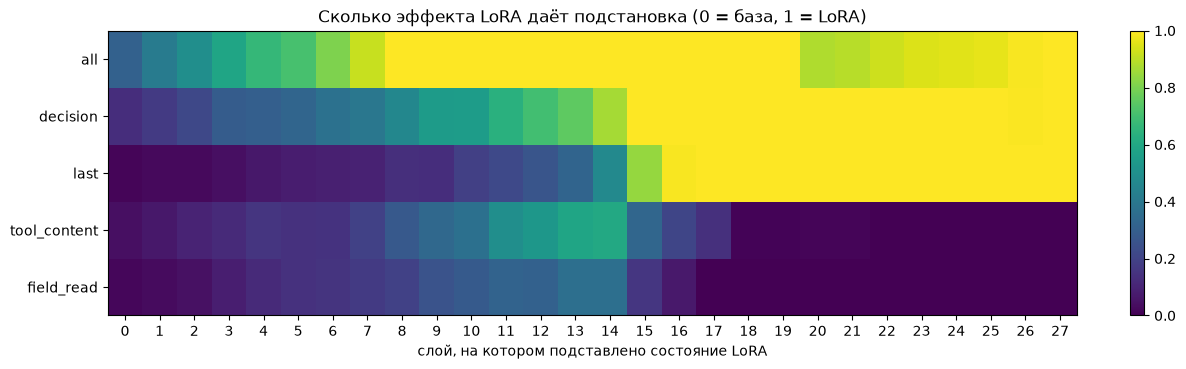

In [4]:
summ = pd.DataFrame(diag["patch_summary"])
viz.patch_heatmap(summ);
summ.pivot(index="set", columns="layer", values="effect").round(2)

### 2. Какой формы изменение, которое делает LoRA

,layer,r2_const,r2_probe,r2_state,r2_linear,rank90_centered,norm_mean
0,0,0.998,0.998,0.998,0.999,51,0.338
1,1,0.999,0.999,0.999,1.000,12,2.085
2,2,0.997,0.997,0.997,0.999,14,2.379
3,3,0.988,0.988,0.988,0.996,20,3.363
4,4,0.985,0.985,0.985,0.996,17,4.092
5,5,0.980,0.980,0.980,0.995,16,4.849
6,6,0.929,0.930,0.930,0.984,13,5.293
7,7,0.944,0.944,0.944,0.987,14,6.587
8,8,0.913,0.913,0.913,0.980,15,8.235
9,9,0.890,0.891,0.890,0.975,15,9.303


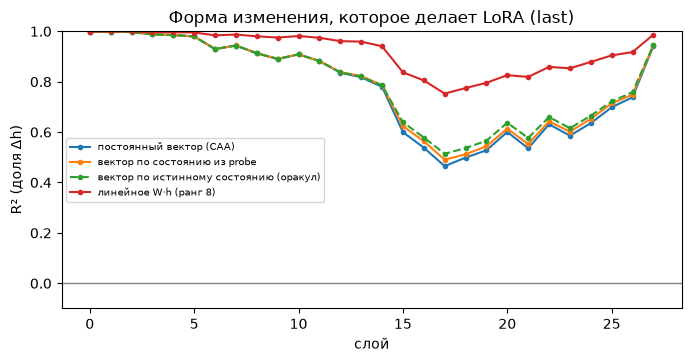

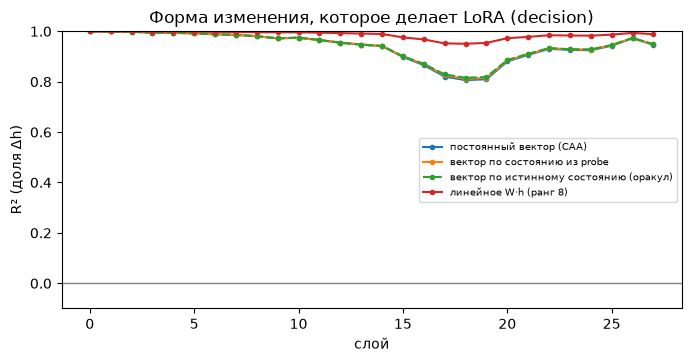

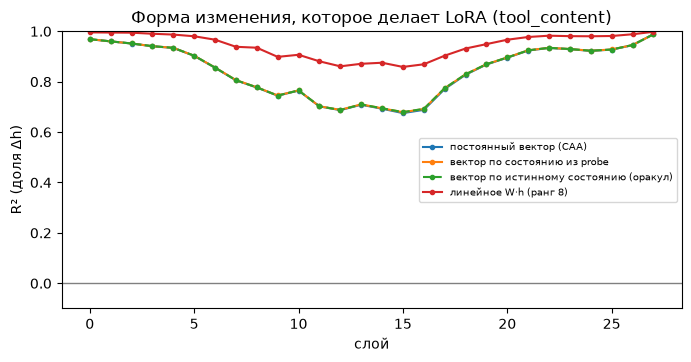

In [5]:
dd = pd.DataFrame(diag["decomposition"])
for pos in ("last", "decision", "tool_content"):
    viz.delta_forms(dd, pos)
dd[dd.position == "last"][["layer", "r2_const", "r2_probe", "r2_state", "r2_linear", "rank90_centered", "norm_mean"]].round(3)

### Поведенческая проверка формы (CV по задачам train)

Добавка в точку решения на лучших по подстановке слоях. `fixed_like_lora` — доля расхождений, где решение стало как у LoRA; `kept_where_agree` — доля совпадений, где решение не сломалось.

In [6]:
pd.DataFrame(diag["form_check"]).round(3)

,layer,form,agree_with_lora,fixed_like_lora,kept_where_agree,n
0,20,const,0.667,0.190,0.989,156
1,20,probe,0.705,0.286,0.989,156
2,20,linear,0.763,0.476,0.957,156
3,20,base,0.596,0.000,1.000,156
4,18,const,0.686,0.238,0.989,156
5,18,probe,0.718,0.349,0.968,156
6,18,linear,0.756,0.444,0.968,156
7,18,base,0.596,0.000,1.000,156
8,19,const,0.673,0.222,0.978,156
9,19,probe,0.737,0.381,0.978,156


## Вывод → журнал

In [7]:
display(Markdown(exp.report(
    conclusion="""**Разведка, train (156 промптов; решения LoRA и базы расходятся в 63).** Решение по первому токену
совпадает с полным скорингом в 100%.

**1. Где живёт эффект LoRA.** В точке решения во второй половине сети. Подстановка состояния LoRA в ОДНУ
позицию (последний токен перед действием) делает решение как у LoRA:

| слой | 8 | 12 | 14 | 16 | 18 | 20 | 21 | 22–27 |
|---|---|---|---|---|---|---|---|---|
| доля расхождений, ставших как у LoRA | 0.17 | 0.19 | 0.25 | 0.48 | 0.57 | 0.65 | 0.87 | 0.98–1.00 |

Окно решения (generation prompt + префикс вызова, ~13 токенов) — то же, чуть раньше. Подстановка в токены
ответа инструмента помогает только до слоя 14 (максимум 0.37 расхождений) и после 15 не действует совсем:
к середине сети нужная информация уже перенесена в позиции решения. Совпадения (контроль, 20 промптов)
подстановка не ломает ни на одном слое.

**2. Какой формы изменение.** Δh = h_LoRA − h_база в последнем токене (R² на отложенных задачах):

| слой | постоянный вектор | по состоянию из probe | по истинному состоянию | линейное W·h, ранг 8 |
|---|---|---|---|---|
| 16 | 0.54 | 0.56 | 0.58 | 0.81 |
| 20 | 0.60 | 0.61 | 0.64 | 0.83 |
| 24 | 0.64 | 0.65 | 0.67 | 0.88 |

Большая часть энергии — постоянный сдвиг, но остальное зависит от входа: линейное отображение состояния
базы объясняет на 0.2–0.3 больше. Бинарное состояние «подходит / не подходит» почти ничего не добавляет
к постоянному вектору (+0.02–0.04): LoRA делает не «если не подходит — толкнуть», а более богатую функцию
от состояния. 90% разброса Δh — в 12–27 направлениях.

**Поведенческая проверка** (добавка Δh, предсказанного в закрытой форме, в одну позицию на слоях 18–20,
CV по задачам, без градиентного обучения): постоянный вектор повторяет 19–24% решений LoRA, вектор по
probe — 29–38%, линейный — 44–48%, сохраняя 96–99% совпадений. Потолок одной позиции на этих слоях
(полное состояние LoRA) — 57–65%; линейный берёт около трёх четвертей потолка. Слои 18–20 выбраны по
среднему эффекту; на слоях 22+ потолок одной позиции ~100%, там проверку ещё не делал.

Чтение: вмешательства в одну позицию поздних слоёв в принципе достаточно; постоянный вектор (класс CAA) —
самая слабая форма, что согласуется с провалом CAA на переносе; линейное отображение состояния, найденное
в закрытой форме, уже повторяет половину эффекта LoRA. Оговорки: train (LoRA училась на этих промптах),
одна модель 1.7B, режим без рассуждения.""",
    next_step="""Методы добавки в активации: (1) проверка формы на слоях 22–26, где потолок одной позиции ~100%;
(2) линейная / низкоранговая интервенция в точке решения, подогнанная в закрытой форме — сначала с LoRA как
учителем (Δh), затем без учителя (из контраста верных и неверных решений базы); (3) ReFT и CAST как
семейства — подбор на val, проверка на новом наборе переноса; цена против LoRA.""",
)))

## 2026-10-28 01:06 · прогон `20261027-214322_lora-diag-qwen3-1.7b_c2afcb`

**Гипотеза:** explore · **Ноутбук:** notebooks/07_lora_diagnostics.ipynb · **Модель:** Qwen/Qwen3-1.7B (mps, float16) · **Режим решения:** scored
**Стадии:** data, baseline, probe, vectors, sweep, fit, diagnose · **git:** `bf8c48a`

**Зачем:** Где и в какой форме LoRA меняет активации: подстановка LoRA → база, разбор Δh.

**Отличия от конфига по умолчанию:** `data.n_tasks` = 160; `eval.methods` = ['baseline', 'strong_prompt', 'restate', 'explicit_state', 'steering', 'steering_gated', 'tact', 'lora']; `model.name` = 'Qwen/Qwen3-1.7B'

**Результаты (val):**

| method | success | sensitivity | specificity | diff_vs_base | ci | fixed | broken | episode | ep_diff | tokens | calls | p50_ms |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| baseline | 0.621 | 0.526 | 0.400 | — |  | — | — | 0.586 | — | 831 | 10.000 | 400.600 |
| strong_prompt | 0.569 | 0.474 | 0.300 | -0.052 | [-0.138, +0.000] | 0.000 | 3.000 | 0.569 | -0.017 | 885 | 10.000 | 291.800 |
| restate | 0.638 | 0.526 | 0.400 | 0.017 | [-0.069, +0.103] | 4.000 | 3.000 | 0.586 | 0.000 | 1765 | 11.000 | 1596.100 |
| explicit_state | 0.552 | 0.474 | 0.100 | -0.069 | [-0.207, +0.069] | 6.000 | 10.000 | 0.466 | -0.121 | 1932 | 11.000 | 3443.700 |
| steering | 0.655 | 0.632 | 0.400 | 0.034 | [+0.000, +0.086] | 2.000 | 0.000 | 0.603 | 0.017 | 831 | 10.000 | 410.200 |
| steering_gated | 0.638 | 0.579 | 0.400 | 0.017 | [+0.000, +0.052] | 1.000 | 0.000 | 0.603 | 0.017 | 831 | 10.000 | 408.600 |
| tact | 0.621 | 0.526 | 0.400 | 0.000 | [+0.000, +0.000] | 0.000 | 0.000 | 0.586 | 0.000 | 831 | 10.000 | 369.600 |
| lora | 0.948 | 1.000 | 0.800 | 0.328 | [+0.190, +0.466] | 19.000 | 0.000 | 0.828 | 0.241 | 831 | 10.000 | 299.000 |

**Вердикты (автоматически, по правилам HYPOTHESES.md):**
- H1: ✔ support — лучший probe L16/post_message: AUROC 0.980, acc 0.882 при перестановке 0.573
- H2: ✔ support — различает (H1), но ошибается в 47% меняющих пар: чувствительность 0.526, специфичность 0.400
- H3: ? inconclusive (val) — на val: успех 0.621 → 0.655 при L16/pre_action/α=1.0; решает только test
- H4: ✘ against (val) — LoRA не хуже steering на условном срезе: steering − LoRA -0.293 [-0.431, -0.155]
- ALT: ? inconclusive (val) — то же качество, что у steering, но дороже: restate (steering − restate +0.017 [-0.052, +0.086]), но дороже: p50 1596 vs 410 мс; explicit_state (steering − explicit_state +0.103 [-0.034, +0.241]), но дороже: p50 3444 vs 410 мс

**Вывод:** **Разведка, train (156 промптов; решения LoRA и базы расходятся в 63).** Решение по первому токену
совпадает с полным скорингом в 100%.

**1. Где живёт эффект LoRA.** В точке решения во второй половине сети. Подстановка состояния LoRA в ОДНУ
позицию (последний токен перед действием) делает решение как у LoRA:

| слой | 8 | 12 | 14 | 16 | 18 | 20 | 21 | 22–27 |
|---|---|---|---|---|---|---|---|---|
| доля расхождений, ставших как у LoRA | 0.17 | 0.19 | 0.25 | 0.48 | 0.57 | 0.65 | 0.87 | 0.98–1.00 |

Окно решения (generation prompt + префикс вызова, ~13 токенов) — то же, чуть раньше. Подстановка в токены
ответа инструмента помогает только до слоя 14 (максимум 0.37 расхождений) и после 15 не действует совсем:
к середине сети нужная информация уже перенесена в позиции решения. Совпадения (контроль, 20 промптов)
подстановка не ломает ни на одном слое.

**2. Какой формы изменение.** Δh = h_LoRA − h_база в последнем токене (R² на отложенных задачах):

| слой | постоянный вектор | по состоянию из probe | по истинному состоянию | линейное W·h, ранг 8 |
|---|---|---|---|---|
| 16 | 0.54 | 0.56 | 0.58 | 0.81 |
| 20 | 0.60 | 0.61 | 0.64 | 0.83 |
| 24 | 0.64 | 0.65 | 0.67 | 0.88 |

Большая часть энергии — постоянный сдвиг, но остальное зависит от входа: линейное отображение состояния
базы объясняет на 0.2–0.3 больше. Бинарное состояние «подходит / не подходит» почти ничего не добавляет
к постоянному вектору (+0.02–0.04): LoRA делает не «если не подходит — толкнуть», а более богатую функцию
от состояния. 90% разброса Δh — в 12–27 направлениях.

**Поведенческая проверка** (добавка Δh, предсказанного в закрытой форме, в одну позицию на слоях 18–20,
CV по задачам, без градиентного обучения): постоянный вектор повторяет 19–24% решений LoRA, вектор по
probe — 29–38%, линейный — 44–48%, сохраняя 96–99% совпадений. Потолок одной позиции на этих слоях
(полное состояние LoRA) — 57–65%; линейный берёт около трёх четвертей потолка. Слои 18–20 выбраны по
среднему эффекту; на слоях 22+ потолок одной позиции ~100%, там проверку ещё не делал.

Чтение: вмешательства в одну позицию поздних слоёв в принципе достаточно; постоянный вектор (класс CAA) —
самая слабая форма, что согласуется с провалом CAA на переносе; линейное отображение состояния, найденное
в закрытой форме, уже повторяет половину эффекта LoRA. Оговорки: train (LoRA училась на этих промптах),
одна модель 1.7B, режим без рассуждения.

**Следующий шаг:** Методы добавки в активации: (1) проверка формы на слоях 22–26, где потолок одной позиции ~100%;
(2) линейная / низкоранговая интервенция в точке решения, подогнанная в закрытой форме — сначала с LoRA как
учителем (Δh), затем без учителя (из контраста верных и неверных решений базы); (3) ReFT и CAST как
семейства — подбор на val, проверка на новом наборе переноса; цена против LoRA.
